# DynamicAuc Simulator Tutorial

This notebook provides a complete walkthrough of the `dynamicauc` simulator. We will cover:

1.  **Basic Simulation**: Running a campaign with a single policy.
2.  **Benchmarking Multiple Policies**: Comparing baselines in a paired experiment.
3.  **Training an RL Agent**: Using Gymnasium and Stable Baselines 3.
4.  **Deep Dive Visualization**: Analyzing a single RL episode to see auction timings, delayed rewards, and state evolution.
5.  **Final Performance Comparison**: Benchmarking the trained RL agent against baselines.
6.  **Command-Line Usage**: Using Hydra for large-scale experiments.

## Setup and Installation

First, ensure `dynamicauc` is installed. For this tutorial, we will also need `stable-baselines3` to train our RL agent and `seaborn` for plotting.

In [1]:
!pip install stable-baselines3[extra] seaborn

In [2]:
import dynamicauc as dac
from dynamicauc.simulator import Simulator
from dynamicauc.policies import FiPlaPolicy, ConstantPolicy, RandomPolicy
from typing import List

import gymnasium as gym
from stable_baselines3 import PPO

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Part 1: Basic Simulation (Single Policy)

The core components of a simulation are a `Scenario` (the environment's rules) and a `BiddingPolicy` (the agent's strategy). We can create a scenario from a built-in preset.

In [3]:
# 1. Create a scenario from a preset
scenario = dac.make("saturation-second-price-uniform")

# 2. Instantiate a policy
policy = FiPlaPolicy()

# 3. Configure and run the simulator
sim = Simulator(scenario, policy, campaign_cfg={
    "n_runs": 10,
    "seed": 42,
})

auctions_df, displays_df, conversions_df, summary_df = sim.run()

print("--- Simulation Summary (FiPla Policy) ---")
summary_df.head()

--- Simulation Summary (FiPla Policy) ---


,run_id,n_auctions,n_wins,win_rate,total_spend,n_conversions,n_immediate,n_delayed
0,0,61,19,0.3115,2.8733,3,0,3
1,1,61,14,0.2295,2.1600,3,0,3
2,2,47,12,0.2553,1.7012,1,0,1
3,3,62,11,0.1774,1.7293,5,0,5
4,4,58,16,0.2759,1.9177,4,0,4


## Part 2: Benchmarking Multiple Policies

The `Simulator` is designed to easily compare multiple policies. By passing a dictionary of policies, the simulator will automatically run all of them in a **paired experiment**. This means for each `run_id`, every policy faces the exact same sequence of auction arrivals and competitor bids, leading to a much fairer and more statistically robust comparison.

In [4]:
# 1. Define a dictionary of policies to compare
policies = {
    "FiPla": FiPlaPolicy(),
    "Constant(0.5)": ConstantPolicy(0.5),
    "Random(2.0)": RandomPolicy(2.0),
}

# 2. Run the simulator with the policy dictionary
multi_policy_sim = Simulator(scenario, policies, campaign_cfg={
    "horizon": 10.0,
    "n_runs": 50, # More runs for better statistics
    "seed": 123,
})

_, _, _, multi_summary_df = multi_policy_sim.run()

# The output summary now includes a 'policy' column
print("--- Multi-Policy Simulation Summary ---")
multi_summary_df.groupby("policy").mean()

--- Multi-Policy Simulation Summary ---


,run_id,n_auctions,n_wins,win_rate,total_spend,n_conversions,n_immediate,n_delayed
policy,,,,,,,,
Constant(0.5),24.5,55.16,27.40,0.495906,6.959734,4.76,0.0,4.76
FiPla,24.5,55.16,12.96,0.236888,1.915064,3.74,0.0,3.74
Random(2.0),24.5,55.16,40.64,0.737160,18.092256,5.44,0.0,5.44


We can now compute aggregate statistics for each policy.

In [5]:
baseline_results = multi_summary_df.groupby("policy").agg(
    mean_conversions=("n_conversions", "mean"),
    std_conversions=("n_conversions", "std"),
    mean_spend=("total_spend", "mean")
).reset_index()

print("--- Aggregate Performance of Baseline Policies ---")
baseline_results

--- Aggregate Performance of Baseline Policies ---


,policy,mean_conversions,std_conversions,mean_spend
0,Constant(0.5),4.76,2.015856,6.959734
1,FiPla,3.74,1.816141,1.915064
2,Random(2.0),5.44,2.408827,18.092256


## Part 3: Training a Reinforcement Learning Agent

A key feature of `dynamicauc` is its `Gymnasium` compatibility, allowing you to train agents with standard RL libraries. Here's the full workflow to train a PPO agent and add it to our benchmark.

### Train the RL Agent

We create a `DynamicAuction-v0` environment and train a `PPO` agent from `stable-baselines3`. The agent will learn a policy by interacting directly with the environment.

In [6]:
env = gym.make("DynamicAuction-v0", scenario=scenario)

# The 'MultiInputPolicy' is required because our observation is a dictionary
model = PPO("MultiInputPolicy", env, verbose=0, seed=42)
print("Training PPO agent...")
model.learn(total_timesteps=20000) # Use more timesteps for better performance
print("Training complete.")

Training PPO agent...
Training complete.


### Step 3.2: Add the Trained Agent to the Benchmark

The `Simulator` can accept any `callable` that takes an observation dictionary and returns a bid. This makes it trivial to integrate our trained model.

We create a simple `lambda` function that wraps the model's `predict` method and add it to our dictionary of policies.

In [7]:
# Create a callable function from the trained model
# model.predict() returns (action, state), so we take the first element.
rl_policy_fn = lambda obs: model.predict(obs, deterministic=True)[0]

policies["PPO_Agent"] = rl_policy_fn

print("Policies to be benchmarked:", list(policies.keys()))

Policies to be benchmarked: ['FiPla', 'Constant(0.5)', 'Random(2.0)', 'PPO_Agent']


### Step 3.3: Run the Full Comparison

Now we run the simulator one last time with all policies, including our new PPO agent.

In [8]:
full_sim = Simulator(scenario, policies, campaign_cfg={
    "horizon": 10.0,
    "n_runs": 100, # Use more runs for a reliable comparison
    "seed": 456,
})

_, _, _, final_summary_df = full_sim.run()

final_results = final_summary_df.groupby("policy").agg(
    mean_conversions=("n_conversions", "mean"),
    std_conversions=("n_conversions", "std"),
    mean_spend=("total_spend", "mean")
).reset_index()

print("--- Final Benchmark Results ---")
final_results

--- Final Benchmark Results ---


,policy,mean_conversions,std_conversions,mean_spend
0,Constant(0.5),4.56,2.239769,6.850258
1,FiPla,3.64,2.096269,1.914220
2,PPO_Agent,0.00,0.000000,0.000000
3,Random(2.0),4.46,2.217561,18.312886


Finally, we create bar plots to visualize the final aggregate performance metrics.

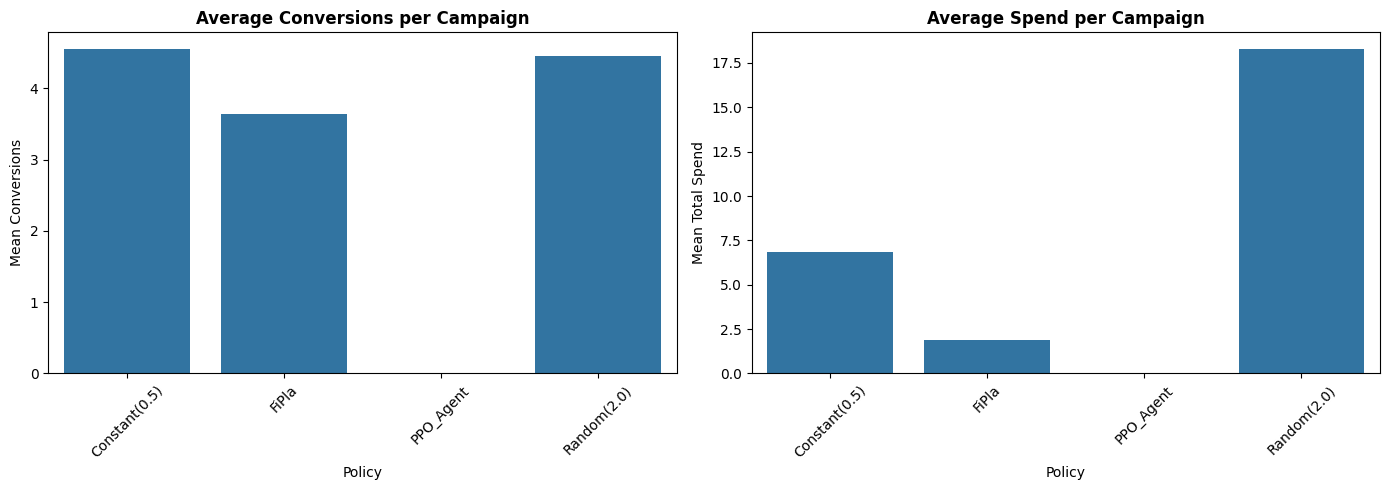

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Plot 1: Mean Conversions
sns.barplot(data=final_results, x="policy", y="mean_conversions", ax=axes[0])
axes[0].set_title("Average Conversions per Campaign", fontweight="bold")
axes[0].set_ylabel("Mean Conversions")
axes[0].set_xlabel("Policy")
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Mean Spend
sns.barplot(data=final_results, x="policy", y="mean_spend", ax=axes[1])
axes[1].set_title("Average Spend per Campaign", fontweight="bold")
axes[1].set_ylabel("Mean Total Spend")
axes[1].set_xlabel("Policy")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Part 6: Using Hydra for Command-Line Simulations

For large-scale experiments, you can use the provided `dynamicauc/main.py` script, which is configured with Hydra. This allows you to easily override any parameter from the command line. The following command runs the default configuration (`conf/config.yaml`), which uses the `fipla` policy.

In [ ]:
!python ../dynamicauc/main.py campaign.n_runs=5

You can easily swap out components. For example, to run with the `constant` policy and a different competition model, you can run:

```bash
python ../dynamicauc/main.py policy=constant competition=lognormal campaign.n_runs=5
```

This is ideal for running sweeps and generating data for research papers.